# 09 — Signal-simulation readiness and speed context

## Problem
Speed measurements alone cannot establish traffic volume, queue length, signal phase, or the effect of changing a green time. A speed map must not be presented as a signal-control simulation.

## Safe solution
Join PEMS-BAY observed speed summaries to the supplied sensor metadata and visualize speed context only. No signal timing, queue simulation, or control benefit is claimed.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
FIG = ROOT / 'results' / 'figures'
METRICS = ROOT / 'results' / 'metrics'
FIG.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)
traffic = pd.read_csv(DATA / 'PEMS-BAY.csv', index_col=0, parse_dates=True)
traffic.columns = traffic.columns.astype(str)
traffic = traffic.apply(pd.to_numeric, errors='coerce').where(lambda values: values > 0)
metadata = pd.read_csv(DATA / 'PEMS-BAY-META.csv', dtype={'sensor_id': str})
metadata['sensor_id'] = metadata['sensor_id'].astype(str)
summary = pd.DataFrame({
    'sensor_id': traffic.columns,
    'mean_speed': traffic.mean().to_numpy(),
    'median_speed': traffic.median().to_numpy(),
    'valid_reading_percent': traffic.notna().mean().to_numpy() * 100
})
sensor_context = metadata.merge(summary, on='sensor_id', how='inner', validate='one_to_one')
assert len(sensor_context) == len(traffic.columns), 'Metadata and traffic sensor IDs do not fully match.'
sensor_context.to_csv(METRICS / 'pems_bay_sensor_speed_summary.csv', index=False)
slowest = sensor_context.nsmallest(12, 'mean_speed')
display(slowest[['sensor_id', 'Name', 'mean_speed', 'median_speed', 'valid_reading_percent']].round(2))
print('Sensor speed context only; flow, queues, signal phases, and cycle timings are unavailable.')

,sensor_id,Name,mean_speed,median_speed,valid_reading_percent
319,400970,LAWRENCE EXPWY,53.95,56.6,100.00
304,400971,Old Bayshore Hwy,54.78,60.5,100.00
248,400895,San Tomas Expwy rm-s-diag,55.76,64.1,100.00
250,400172,De La Cruz Blvd rm-s-diag,56.00,62.8,100.00
184,407373,Homestead Dr off-s-diag,56.06,59.0,99.99
246,400372,Great America Pkwy rm-s-loop,56.57,63.0,100.00
249,400586,Trimble Rd. rm-s-loop,56.63,64.4,100.00
31,407339,W Fremont Ave rm-s-diag,56.67,62.8,99.99
53,400664,Almaden Expwy rm-n-diag,56.72,61.1,100.00
10,400461,ALMADEN EXPWY RM-N-DIA,56.80,59.9,100.00


Sensor speed context only; flow, queues, signal phases, and cycle timings are unavailable.


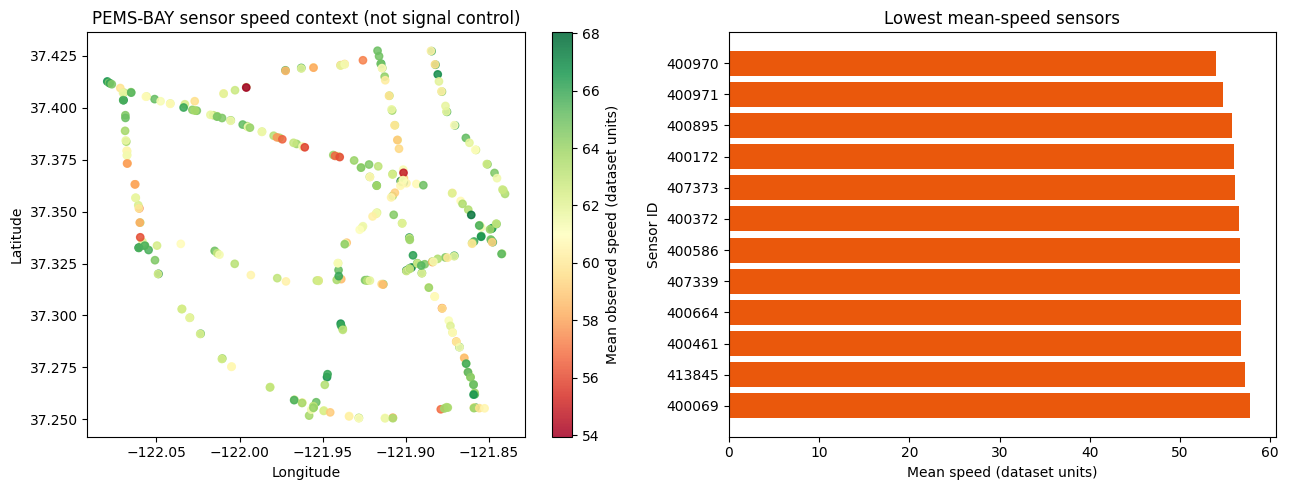

Saved results/figures/24_pems_bay_speed_context.png
A real signal simulation requires traffic volume/queues, phases, and signal timing plans.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
points = axes[0].scatter(
    sensor_context['Longitude'], sensor_context['Latitude'],
    c=sensor_context['mean_speed'], cmap='RdYlGn', s=28, alpha=.85
)
fig.colorbar(points, ax=axes[0], label='Mean observed speed (dataset units)')
axes[0].set(title='PEMS-BAY sensor speed context (not signal control)', xlabel='Longitude', ylabel='Latitude')
axes[1].barh(slowest['sensor_id'].astype(str), slowest['mean_speed'], color='#ea580c')
axes[1].invert_yaxis()
axes[1].set(title='Lowest mean-speed sensors', xlabel='Mean speed (dataset units)', ylabel='Sensor ID')
fig.tight_layout()
fig.savefig(FIG / '24_pems_bay_speed_context.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved results/figures/24_pems_bay_speed_context.png')
print('A real signal simulation requires traffic volume/queues, phases, and signal timing plans.')